In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar el paquete `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 01 · Caso de negocio — Retención de asociados en Confiar

Antes de modelar, el proyecto necesita **una pregunta de negocio, un costo de equivocarse expresado en dinero,
una línea base y una métrica**. Este notebook deja esas cuatro cosas escritas con números; su resumen es la ficha
de caso (`reports/00_caso.md`).

Para dimensionar el problema se leen **solo tres columnas** del dataset: la variable objetivo, el saldo de aportes y
el mes del registro. El análisis completo de los datos es el notebook 02.

## 1. La pregunta de negocio

**Contexto.** En Confiar los aportes sociales son la expresión concreta del vínculo asociativo y parte del capital de
la cooperativa. Cuando un asociado radica la **solicitud de retiro total**, se lleva sus aportes y termina la relación.
Hoy existe un protocolo de atención para quien quiere retirarse, pero es **reactivo**: se activa cuando el asociado ya
está radicando.

| Pregunta | Respuesta |
|---|---|
| **¿Quién decide?** | El **área comercial y de mercadeo** (equipo de fidelización), que diseña y ejecuta las campañas de retención |
| **¿Qué decide?** | Cada mes, **a qué asociados incluir en una campaña proactiva** (llamada del asesor, mensaje, beneficio) **antes** de que radiquen |
| **¿Con qué información?** | El perfil del asociado: productos y saldos (aportes, ahorro, cuenta, crédito), transacciones, visitas a sucursal y datos sociodemográficos |
| **¿Qué pasa hoy, sin modelo?** | Nadie se contacta antes de tiempo: la cooperativa se entera cuando el asociado ya está radicando |

> **Pregunta de negocio:** *¿Qué asociados tienen mayor probabilidad de radicar la solicitud de retiro total, para que
> el equipo de fidelización los contacte primero y conserve la mayor cantidad posible de aportes con el presupuesto de
> la campaña?*

**Tipo de problema:** clasificación binaria (`sol_retiro`: 1 = radica, 0 = no radica). Lo que se usa del modelo es la
**probabilidad**, para ordenar la lista de contacto. **El modelo no decide solo:** prioriza; el asesor decide a quién
llama y cómo.

## 2. ¿Qué se pierde cuando un asociado se va?

Medimos cuántos asociados radicaron y cuántos aportes tenían en el momento de radicar.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto.config import CONTACT_COST, MONEY_UNIT, RAW_FILE, RETENTION_RATE, TARGET
from proyecto.viz import CHURN, LIGHT, NEUTRAL, STAY, SUBTEXT, fmt_num, fmt_pct, note, pct_axis, set_style, table, titled

set_style()
pd.set_option("display.width", 160)

# Solo tres columnas: el objetivo, el saldo de aportes y el mes del registro (sin el Nit ni otros datos)
data = pd.read_excel(RAW_FILE, usecols=[TARGET, "saldo_aportes", "anio_mes_proceso"])
data["year"] = data["anio_mes_proceso"].str[:4].astype(int)

n = len(data)
filers = data[data[TARGET] == 1]
rate = data[TARGET].mean()
value = data["saldo_aportes"]
print(f"Asociados en el dataset (vinculados 2017–2025): {fmt_num(n)}")
print(f"Radicaron solicitud de retiro total:             {fmt_num(len(filers))} ({fmt_pct(rate)})")
print(f"Aportes de quienes radicaron, al radicar:        {fmt_num(filers['saldo_aportes'].sum(), 1)} {MONEY_UNIT}")
print(f"   promedio por asociado: {fmt_num(filers['saldo_aportes'].mean(), 3)} · mediana: {fmt_num(filers['saldo_aportes'].median(), 3)}")

Asociados en el dataset (vinculados 2017–2025): 194.073
Radicaron solicitud de retiro total:             40.591 (20,9 %)
Aportes de quienes radicaron, al radicar:        47.315,3 millones de COP
   promedio por asociado: 1,166 · mediana: 0,607


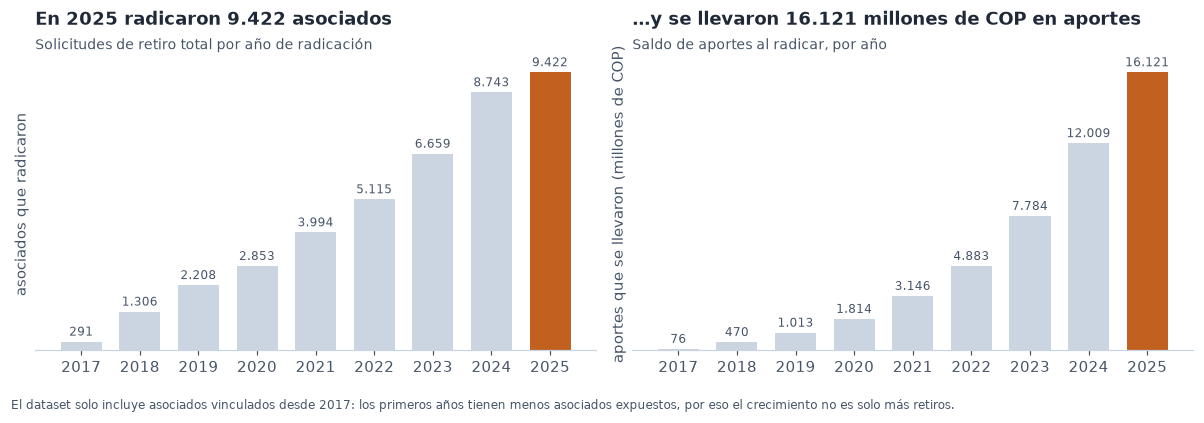

In [3]:
by_year = filers.groupby("year").agg(asociados=(TARGET, "size"), aportes=("saldo_aportes", "sum"))
last = by_year.iloc[-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, label, fmt in [
    (axes[0], "asociados", "asociados que radicaron", lambda v: fmt_num(v)),
    (axes[1], "aportes", f"aportes que se llevaron ({MONEY_UNIT})", lambda v: fmt_num(v)),
]:
    colors = [LIGHT] * (len(by_year) - 1) + [CHURN]
    bars = ax.bar(by_year.index.astype(str), by_year[col], color=colors, width=0.7)
    ax.bar_label(bars, labels=[fmt(v) for v in by_year[col]], fontsize=8, color=SUBTEXT, padding=2)
    ax.set_ylabel(label)
    ax.grid(axis="x", visible=False)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
titled(axes[0], f"En 2025 radicaron {fmt_num(last['asociados'])} asociados", "Solicitudes de retiro total por año de radicación")
titled(axes[1], f"…y se llevaron {fmt_num(last['aportes'])} {MONEY_UNIT} en aportes", "Saldo de aportes al radicar, por año")
plt.tight_layout()
note(fig, "El dataset solo incluye asociados vinculados desde 2017: los primeros años tienen menos asociados expuestos, "
          "por eso el crecimiento no es solo más retiros.")
plt.show()

**Lectura.** El retiro total no es marginal: en el último año completo del dataset (2025) radicaron más de nueve mil
asociados y se llevaron más de dieciséis mil millones de pesos en aportes (cifras exactas en el gráfico). El crecimiento
año a año hay que leerlo con cuidado: el dataset solo contiene asociados vinculados desde 2017, así que cada año hay
más asociados "expuestos" a retirarse.

> **Unidad monetaria.** Los saldos están en **millones de pesos**. No viene escrito en el dataset: se deduce de los
> ingresos, cuyos valores más frecuentes coinciden exactamente con el salario mínimo de cada año (notebook 02,
> sección 4). El equipo debe confirmarlo con la fuente.

¿Pesan igual todos los retiros?

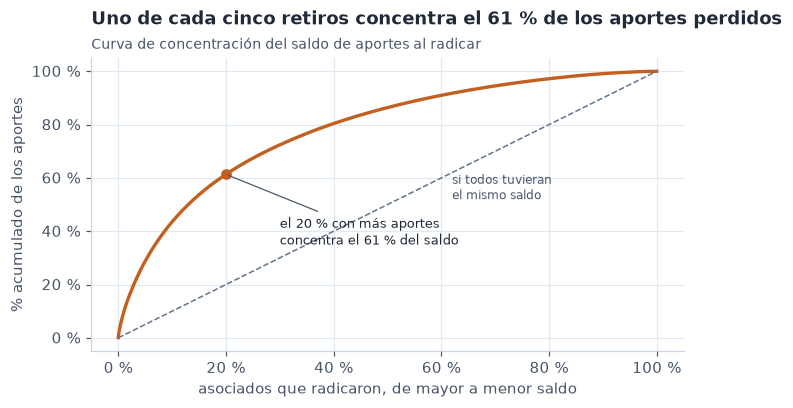

In [4]:
sorted_value = np.sort(filers["saldo_aportes"].to_numpy())[::-1]
cum_share = np.cumsum(sorted_value) / sorted_value.sum()
people_share = np.arange(1, len(sorted_value) + 1) / len(sorted_value)
top20 = cum_share[int(0.2 * len(sorted_value)) - 1]

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(people_share, cum_share, color=CHURN, lw=2.2)
ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1)
ax.text(0.62, 0.52, "si todos tuvieran\nel mismo saldo", color=SUBTEXT, fontsize=8, rotation=0)
ax.scatter([0.2], [top20], color=CHURN, zorder=3)
ax.annotate(f"el 20 % con más aportes\nconcentra el {fmt_pct(top20, 0)} del saldo",
            xy=(0.2, top20), xytext=(0.3, 0.35), fontsize=8.5, color="#1F2937",
            arrowprops={"arrowstyle": "-", "color": SUBTEXT, "lw": 0.8})
pct_axis(ax, "x"); pct_axis(ax, "y")
ax.set_xlabel("asociados que radicaron, de mayor a menor saldo"); ax.set_ylabel("% acumulado de los aportes")
titled(ax, f"Uno de cada cinco retiros concentra el {fmt_pct(top20, 0)} de los aportes perdidos",
       "Curva de concentración del saldo de aportes al radicar")
plt.tight_layout(); plt.show()

**Lectura.** Los retiros no pesan lo mismo: una quinta parte de quienes radican concentra la mayoría de los aportes
(cifra exacta en el título). Por eso la decisión de a quién contactar **no debe depender solo de la probabilidad de
radicar, sino también de cuánto saldo se arriesga**. Esa idea entra en la métrica de la sección 6.

## 3. Equivocarse no cuesta lo mismo

| Resultado | Qué significa | Qué cuesta |
|---|---|---|
| **Verdadero positivo (VP)** | iba a radicar y se contacta | el contacto; a cambio, con cierta probabilidad desiste y conserva sus aportes |
| **Falso positivo (FP)** | no iba a radicar y se contacta | el costo del contacto, sin recuperar nada (aunque refuerza el vínculo) |
| **Falso negativo (FN)** | iba a radicar y no se contacta | la oportunidad de conservar sus aportes |
| **Verdadero negativo (VN)** | no iba a radicar y no se contacta | nada |

Para llevarlo a dinero hacen falta dos cifras que **no están en los datos**. Se fijan como **supuestos de trabajo**,
se reportan siempre a la vista y se ponen a prueba en la sección 5:

- **Costo de un contacto:** $30.000 (llamada del asesor más un detalle).
- **Efectividad de la retención:** de cada 10 asociados que iban a radicar y se contactan, **2 desisten** (20 %).

Ambas deben reemplazarse por cifras reales: el costo lo conoce el área de mercadeo, y la efectividad se mide con
un **piloto con grupo de control** (contactar a la mitad de los asociados marcados y comparar).

In [5]:
from proyecto.models.business import cost_matrix

mean_value = filers["saldo_aportes"].mean()
cm = cost_matrix(mean_value, CONTACT_COST, RETENTION_RATE)
print(f"Supuestos: costo por contacto = {fmt_num(CONTACT_COST, 2)} {MONEY_UNIT} · efectividad = {fmt_pct(RETENTION_RATE, 0)}")
print(f"Saldo promedio de aportes de quien radica = {fmt_num(mean_value, 3)} {MONEY_UNIT}\n")
print("Matriz de costos frente a una decisión perfecta (filas = lo que pasó, columnas = lo que se decidió):")
display(table(cm, decimals=3))
ratio = cm.iloc[1, 0] / cm.iloc[0, 1]
print(f"Dejar pasar a quien va a radicar cuesta {fmt_num(ratio, 1)} veces más que contactar a quien no lo iba a hacer.")

Supuestos: costo por contacto = 0,03 millones de COP · efectividad = 20 %
Saldo promedio de aportes de quien radica = 1,166 millones de COP

Matriz de costos frente a una decisión perfecta (filas = lo que pasó, columnas = lo que se decidió):


,no contactar,contactar
real: no radica,"0,000","0,030"
real: radica,"0,203","0,000"


Dejar pasar a quien va a radicar cuesta 6,8 veces más que contactar a quien no lo iba a hacer.


**Cómo se construye la matriz.**

- **FN** = lo que se deja de ganar por no contactar a quien radica: 20 % × saldo promedio − costo del contacto.
- **FP** = el costo del contacto, que se paga sin recuperar nada.

El error caro es el **falso negativo**: dejar pasar a un asociado que se va cuesta varias veces más que llamar a uno
que se iba a quedar (la proporción exacta está en la salida de arriba). Por eso el modelo debe privilegiar
**encontrar** a quienes van a radicar, aceptando algunas llamadas de más.

## 4. Línea base: ¿contra qué competimos?

Una métrica sola no dice nada. Calculamos el resultado económico de cuatro estrategias **sin modelo**:

- **Sin campaña:** lo que se hace hoy (protocolo reactivo). Beneficio cero por definición.
- **Contactar a todos.**
- **Contactar al azar** al 20 % de los asociados.
- **Perfecta:** contactar solo a quienes van a radicar y tienen saldo suficiente para que valga la pena. Es un techo
  teórico, ningún modelo lo alcanza.

In [6]:
from proyecto.models.business import baseline_strategies

base = baseline_strategies(data[TARGET], value, CONTACT_COST, RETENTION_RATE, share=0.2)
per_1000 = (base[["contactados", "valor_conservado", "costo_campaña", "beneficio_neto"]] / n * 1000).astype(float)
per_1000.columns = ["contactos", "valor conservado", "costo", "beneficio neto"]
print(f"Por cada 1.000 asociados evaluados ({MONEY_UNIT}):")
display(table(per_1000, decimals=2))

accuracy_nobody = 1 - rate
print(f"Exactitud (accuracy) de responder siempre 'no radica': {fmt_pct(accuracy_nobody)}")

Por cada 1.000 asociados evaluados (millones de COP):


,contactos,valor conservado,costo,beneficio neto
Sin campaña (protocolo reactivo actual),"0,00","0,00","0,00","0,00"
Contactar a todos,"1.000,00","48,76","30,00","18,76"
Contactar al azar al 20 %,"200,00","9,54","6,00","3,54"
Perfecta (techo teórico),"190,19","48,39","5,71","42,68"


Exactitud (accuracy) de responder siempre 'no radica': 79,1 %


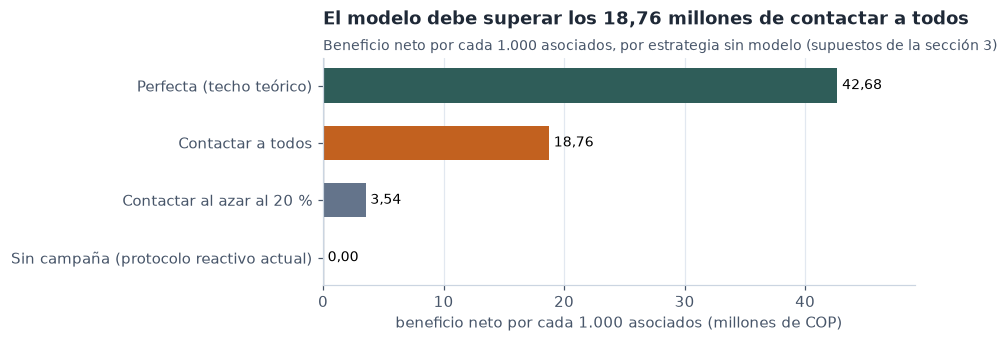

In [7]:
order = per_1000["beneficio neto"].sort_values()
colors = [STAY if "Perfecta" in k else (CHURN if "todos" in k else NEUTRAL) for k in order.index]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
bars = ax.barh(order.index, order.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[fmt_num(v, 2) for v in order.values], padding=3, fontsize=9)
ax.axvline(0, color=SUBTEXT, lw=0.8)
ax.set_xlabel(f"beneficio neto por cada 1.000 asociados ({MONEY_UNIT})")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, order.max() * 1.15)
mass = per_1000.loc["Contactar a todos", "beneficio neto"]
titled(ax, f"El modelo debe superar los {fmt_num(mass, 2)} millones de contactar a todos",
       "Beneficio neto por cada 1.000 asociados, por estrategia sin modelo (supuestos de la sección 3)")
plt.tight_layout(); plt.show()

**Lo que dice la línea base.**

1. **El punto de comparación no es "no hacer nada", es "contactar a todos".** Con estos supuestos, una campaña masiva
   ya deja ganancia: el saldo que se conserva supera lo que cuestan las llamadas. El modelo solo se justifica si
   **supera** a esa campaña masiva, es decir, si consigue casi la misma recuperación con muchos menos contactos.
2. **Hay espacio para el modelo.** La estrategia perfecta deja más del doble de beneficio que la masiva porque llama
   a una fracción de los asociados (ver la columna *contactos*). Esa brecha es lo que un buen modelo puede capturar.
3. **Contactar al azar no sirve:** cada contacto vale lo mismo que en la campaña masiva, pero se alcanza a muy pocos
   de los que se van.
4. **La exactitud no sirve como métrica.** Responder siempre "no radica" acierta casi el 80 % de las veces (cifra
   exacta arriba) y no encuentra a nadie. Un modelo útil puede tener **menos** exactitud que ese y valer mucho más.

## 5. ¿Qué tan frágiles son los supuestos?

La conclusión anterior depende del costo del contacto y de la efectividad. Variamos ambos y miramos dos cosas: el
**costo máximo por contacto** con el que una campaña masiva deja de dar pérdida, y cuánto espacio le queda al modelo.

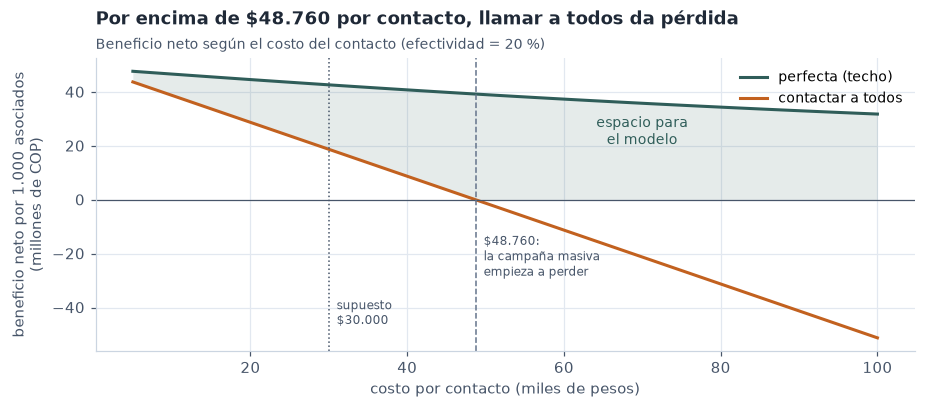

,costo máximo por contacto para que la campaña masiva no pierda (pesos)
efectividad de la retención,
10 %,24.380
20 %,48.760
30 %,73.140


In [8]:
costs = np.linspace(0.005, 0.10, 40)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
mass_line = [baseline_strategies(data[TARGET], value, c, RETENTION_RATE).loc["Contactar a todos", "beneficio_neto"] / n * 1000 for c in costs]
best_line = [baseline_strategies(data[TARGET], value, c, RETENTION_RATE).loc["Perfecta (techo teórico)", "beneficio_neto"] / n * 1000 for c in costs]
ax.fill_between(costs * 1e3, np.maximum(mass_line, 0), best_line, color=STAY, alpha=0.12, lw=0)
ax.plot(costs * 1e3, best_line, color=STAY, lw=2, label="perfecta (techo)")
ax.plot(costs * 1e3, mass_line, color=CHURN, lw=2, label="contactar a todos")
ax.axhline(0, color=SUBTEXT, lw=0.8)
breakeven = rate * RETENTION_RATE * mean_value
ax.axvline(breakeven * 1e3, color=NEUTRAL, ls="--", lw=1)
ax.text(breakeven * 1e3 + 1, min(mass_line) * 0.55, f"${fmt_num(breakeven * 1e6)}:\nla campaña masiva\nempieza a perder",
        fontsize=8, color=SUBTEXT)
ax.axvline(CONTACT_COST * 1e3, color=SUBTEXT, ls=":", lw=1)
ax.text(CONTACT_COST * 1e3 + 1, min(mass_line) * 0.9, "supuesto\n$30.000", fontsize=8, color=SUBTEXT)
ax.text(70, (best_line[28] + max(mass_line[28], 0)) / 2 + 3, "espacio para\nel modelo", color=STAY, fontsize=9, ha="center")
ax.set_xlabel("costo por contacto (miles de pesos)")
ax.set_ylabel("beneficio neto por 1.000 asociados\n(millones de COP)")
ax.legend(loc="upper right")
titled(ax, f"Por encima de ${fmt_num(breakeven * 1e6)} por contacto, llamar a todos da pérdida",
       f"Beneficio neto según el costo del contacto (efectividad = {fmt_pct(RETENTION_RATE, 0)})")
plt.tight_layout(); plt.show()

rows = []
for eff in [0.10, 0.20, 0.30]:
    rows.append({"efectividad de la retención": fmt_pct(eff, 0),
                 "costo máximo por contacto para que la campaña masiva no pierda (pesos)": fmt_num(rate * eff * mean_value * 1e6)})
display(pd.DataFrame(rows).set_index("efectividad de la retención"))

**Lectura.** El costo máximo para que una campaña masiva no pierda es **tasa de radicación × efectividad × saldo
promedio** (tabla de arriba). Si el contacto es una llamada barata y la efectividad es alta, llamar a todos puede ser
rentable. Si el contacto incluye un beneficio costoso o la efectividad es baja, la campaña masiva da pérdida y **solo una
lista priorizada tiene sentido**. En todos los escenarios queda espacio entre la campaña masiva y el techo: ese espacio
es lo que el modelo tiene que ganar.

**Implicación práctica:** el valor del modelo no depende de que los supuestos sean exactos, pero **la cifra en pesos sí**.
Por eso el piloto con grupo de control (sección 3) es parte del proyecto, no un adorno.

## 6. Cómo se medirá el éxito

Dos familias de métricas que se hablan entre sí: las **de negocio** dicen cuánto vale el modelo; las **técnicas**
controlan que no haga trampa con una clase.

**Regla de decisión.** No se contacta a quien supere un umbral fijo de 0,5: se contacta a quien deja **valor esperado
positivo**, es decir, cuando *probabilidad de radicar × efectividad × saldo de aportes > costo del contacto*. Dos
asociados con la misma probabilidad no valen lo mismo si uno tiene diez veces más aportes. Como la regla usa la
probabilidad como número, el modelo tiene que estar **bien calibrado** (si dice 30 %, deben radicar cerca de 3 de cada 10).

| Tipo | Métrica | Qué responde | Meta |
|---|---|---|---|
| **Negocio (principal)** | **Beneficio neto por cada 1.000 asociados** (millones de COP) con la regla de valor esperado | ¿cuánto deja la campaña guiada por el modelo? | superar a "contactar a todos" por más que la variación entre pliegues |
| Negocio | Saldo de aportes en riesgo cubierto (%) | ¿qué parte del dinero que se va alcanzamos a tocar? | reportar junto con el número de contactos |
| Negocio | Contactos necesarios (por 1.000) | ¿cabe en la capacidad del equipo? | dentro de la capacidad que defina mercadeo |
| **Técnica (control principal)** | **PR-AUC** (promedio de precisión) | ¿la lista ordenada pone primero a quienes radican? | muy por encima de la tasa base (≈ 0,21) |
| Técnica | ROC-AUC | ¿ordena bien el riesgo en general? | > 0,5 con holgura |
| Técnica | Recall y precisión de "radica" en el punto de operación | ¿a cuántos encontramos y cuántas llamadas sobran? | siempre reportadas con su umbral |
| Técnica | Lift en el 10 % y 20 % superior | ¿cuántas veces mejor que llamar al azar? | > 1 con holgura |
| Técnica | Puntaje de Brier y curva de calibración | ¿las probabilidades son creíbles? | necesaria para la regla de valor esperado |

**No se usa exactitud (accuracy):** premia al modelo que nunca encuentra a nadie.

## 7. Lo que podría salir mal

- **Fuga de información.** El dataset fotografía a quien radica *en el mes en que radica* y a quien sigue activo en
  diciembre de 2025. Las fechas del registro (`anio_mes_proceso` y `cohorte`) delatan la respuesta y algunas variables se
  calculan incluyendo el mes de radicación (visitas a sucursal, mínimo del saldo de crédito). El notebook 02 lo mide; el
  03 lo demuestra.
- **Sesgos y equidad.** El dataset trae sexo, edad, zona, educación y tipo de ocupación. El modelo **no debe usarse para
  dejar de atender** a ningún grupo: se revisará el error por segmento en la etapa de validación.
- **Datos personales.** El `Nit` (documento) se elimina al cargar. Ningún notebook lo muestra.
- **Asociación no es causalidad.** El modelo dice quién se parece a quienes se fueron, no por qué se van ni si una
  llamada los hará quedarse. Eso solo lo dice el piloto con grupo de control.
- **Hasta dónde decide el modelo.** Ordena la lista; **el asesor decide** a quién contacta y qué le ofrece.

## 8. Cierre

- [x] Pregunta, quién decide y costos escritos **con números** (secciones 1 a 3).
- [x] Línea base calculada: el modelo debe superar a la campaña masiva (sección 4).
- [x] Supuestos a la vista y puestos a prueba (sección 5).
- [x] Métrica principal elegida y justificada (sección 6).
- [x] Resumen en `reports/00_caso.md`.
- [ ] Reemplazar los dos supuestos por cifras reales (costo con mercadeo; efectividad con el piloto).

**Siguiente:** `02_eda.ipynb`.